In [1]:
import mne
import pickle
import pathlib

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

from scripts import paper_style  # two-column paper style for every figure (sizes/font in scripts/paper_style.py)
from scripts.paper_style import TEXT_W, enforce_font_sizes
from scripts.dataset_manager import read_raw_dataset

# Comparing free variables

## Short Plot Introduction

### Grad-average ERP

These plots show the averaged signal across the filtered sets of trials. Single-trials are noisy. With this representation, we can get a feeling for if there is actually something hidden behind the noise.

It has to be noted, that the spread of the values is very important, as they have a big impact on how well the signals will actually be classifiable.

### Topomap sequence

A sequence of topomaps show where the signal intensity actually is. Depending on the parameters, the topomap either show the instantaneous amplitude at T, or the average over a defined window +- the given timestamp.

The amplitudes are taken from the average over all filtered/grouped epochs, which are also shown in the line plot.

### Time-frequency representation

This representation helps figuring out if there is something hidden in the time-frequency domain.

### Statistically-thresholded difference plot


In [2]:
# region helping and comparison functions

raw_dataset = None
RAW_DATASET_NAME = pathlib.Path('data/raw_dataset')
EPOCH_DATASET_NAME = pathlib.Path('data/epoch_dataset')
EPOCH_FILTERED_DATASET_NAME = pathlib.Path('data/epoch_dataset_filtered')

def iter_sessions(d):
    """Yield (subject, session, value) over the nested dict, sorted."""
    for sub in sorted(d):
        for ses in sorted(d[sub]):
            yield sub, ses, d[sub][ses]

def merge_epochs_dict(epochs_dict):
    """Merges the dict of epochs into a single epoch object, preserving subject and session identification in the metadata."""
    all_epochs = []

    for subj, sessions in epochs_dict.items():
        for sess, ep in sessions.items():
            ep = ep.copy()

            # build/extend metadata with subject + session
            n = len(ep)
            extra = pd.DataFrame(
                {"subject": [subj] * n, "session": [sess] * n},
                index=ep.metadata.index if ep.metadata is not None else range(n),
            )

            if ep.metadata is None:
                ep.metadata = extra
            else:
                # avoid clobbering if these columns already exist
                meta = ep.metadata.copy()
                meta["subject"] = subj
                meta["session"] = sess
                ep.metadata = meta

            all_epochs.append(ep)

    merged = mne.concatenate_epochs(all_epochs)
    return merged

def plot_mean_signal(epochs, query=None, group_by=None, title=None, picks=None, show_points=False, point_alpha=0.03, point_size=2, figsize_per_axes=(1.3, 1.1), cmap="tab10", y_buffer_frac=0.2, spread="sem", spread_alpha=0.25):
    if epochs.metadata is None:
        raise ValueError("epochs.metadata is None; metadata is required for filter/group.")
    if spread not in (None, "sem", "std"):
        raise ValueError("spread must be None, 'sem', or 'std'.")

    # --- filter ---
    ep = epochs.copy()
    if query is not None:
        keep_idx = ep.metadata.query(query).index
        mask = ep.metadata.index.isin(keep_idx)
        ep = ep[mask]

    if len(ep) == 0:
        raise ValueError("No epochs left after applying query.")

    # --- picks ---
    if picks is None:
        picks = ep.ch_names
        picks.remove("Fz")

    # --- groups ---
    if group_by:
        groups = list(ep.metadata[group_by].dropna().unique())
        try:
            groups = sorted(groups)
        except TypeError:
            pass
    else:
        groups = [None]  # single pseudo-group meaning "all epochs"

    n_groups = len(groups)
    n_ch = len(picks)

    times = ep.times

    # MNE stores data in volts internally; convert to microvolts for display.
    VOLTS_TO_MICROVOLTS = 1e6
    data = ep.get_data(picks=picks) * VOLTS_TO_MICROVOLTS  # (n_epochs, n_channels, n_times)

    # --- compute means (+ spread) per group ---
    means = {}
    spreads = {}
    all_group_data = {}
    for g in groups:
        if g is None:
            g_mask = np.ones(len(ep), dtype=bool)
        else:
            g_mask = (ep.metadata[group_by] == g).values
        g_data = data[g_mask]  # (n_epochs_g, n_ch, n_times)
        means[g] = g_data.mean(axis=0)  # (n_ch, n_times)
        all_group_data[g] = g_data

        if spread == "sem":
            n_trials = g_data.shape[0]
            spreads[g] = g_data.std(axis=0, ddof=1) / np.sqrt(n_trials) if n_trials > 1 else np.zeros_like(means[g])
        elif spread == "std":
            spreads[g] = g_data.std(axis=0, ddof=1) if g_data.shape[0] > 1 else np.zeros_like(means[g])
        else:
            spreads[g] = None

    # --- y-limits: include mean +/- spread so the band isn't clipped ---
    if spread is not None:
        lo_stacked = np.stack([means[g] - spreads[g] for g in groups])
        hi_stacked = np.stack([means[g] + spreads[g] for g in groups])
        mean_min = lo_stacked.min()
        mean_max = hi_stacked.max()
    else:
        all_means_stacked = np.stack(list(means.values()))  # (n_groups, n_ch, n_times)
        mean_min = all_means_stacked.min()
        mean_max = all_means_stacked.max()

    mean_range = mean_max - mean_min
    pad = y_buffer_frac * mean_range if mean_range > 0 else 1.0
    ylim = (mean_min - pad, mean_max + pad)
    xlim = (times[0], times[-1])

    # --- colors per group ---
    cmap_obj = plt.get_cmap(cmap)
    colors = {g: cmap_obj(i % cmap_obj.N) for i, g in enumerate(groups)}

    # --- build grid: rows = groups, cols = channels ---
    fig, axes = plt.subplots(
        n_groups,
        n_ch,
        figsize=(figsize_per_axes[0] * n_ch, figsize_per_axes[1] * n_groups),
        sharex=True,
        sharey=True,
        squeeze=False,
    )

    for row, g in enumerate(groups):
        color = colors[g]
        g_data = all_group_data[g]  # (n_epochs_g, n_ch, n_times), in microvolts
        mean_g = means[g]  # (n_ch, n_times), in microvolts
        spread_g = spreads[g]  # (n_ch, n_times) or None

        for col, ch in enumerate(picks):
            ax = axes[row, col]

            if show_points:
                # Faint scatter of every trial's raw samples. Points may fall
                # outside ylim (e.g. artifacts) — that's fine, they'll just
                # be clipped since the axis is intentionally scaled to the mean.
                n_trials = g_data.shape[0]
                x_tiled = np.tile(times, n_trials)
                y_flat = g_data[:, col, :].ravel()
                ax.scatter(
                    x_tiled,
                    y_flat,
                    s=point_size,
                    alpha=point_alpha,
                    color=color,
                    linewidths=0,
                    rasterized=True,
                    clip_on=True,
                )
            if spread_g is not None:
                ax.fill_between(
                    times,
                    mean_g[col] - spread_g[col],
                    mean_g[col] + spread_g[col],
                    color=color,
                    alpha=spread_alpha,
                    linewidth=0,
                )

            ax.plot(times, mean_g[col], color=color, linewidth=1.0)
            ax.axhline(0, color="k", linewidth=0.5, alpha=0.3)
            ax.axvline(0, color="k", linewidth=0.5, alpha=0.3)

            if row == 0:
                ax.set_title(ch)
            if col == 0:
                ylabel = f"{g}\nAmplitude (µV)" if g is not None else "Amplitude (µV)"
                ax.set_ylabel(ylabel)
            if row == n_groups - 1:
                ax.set_xlabel("Time (s)")

    for ax in axes.ravel():
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)

    if title is not None:
        fig.suptitle(f'Average signals per electrode - {title}')
    else:
        fig.suptitle(f'Average signals per electrode')
    fig.tight_layout()
    return fig, axes

def plot_compare_evokeds_grid(epochs, query=None, group_by=None, picks=None, title="", combine=None, ci=0.95, figsize_per_axes=None, cmap="tab10", n_cols=None):
    """Compare average signal, grouped by conditions."""
    if group_by and epochs.metadata is None:
        raise ValueError("epochs.metadata is None; metadata is required for grouping.")

    # --- filter ---
    ep = epochs.copy()
    if query is not None:
        if epochs.metadata is None:
            raise ValueError("epochs.metadata is None; metadata is required for filter.")
        keep_idx = ep.metadata.query(query).index
        mask = ep.metadata.index.isin(keep_idx)
        ep = ep[mask]

    if len(ep) == 0:
        raise ValueError("No epochs left after applying query.")

    # --- picks ---
    if picks is None:
        picks = ep.ch_names.copy()
        picks.remove('Fz')
    elif isinstance(picks, str):
        picks = [picks]

    # --- build evokeds dict: {label: list[Evoked]} ---
    if group_by:
        levels = list(ep.metadata[group_by].dropna().unique())
        try:
            levels = sorted(levels)
        except TypeError:
            pass
        evokeds = {
            str(lvl): list(ep[ep.metadata[group_by] == lvl].iter_evoked())
            for lvl in levels
        }
    else:
        evokeds = {"all": list(ep.iter_evoked())}

    # --- colors per group, consistent across channels ---
    cmap_obj = plt.get_cmap(cmap)
    colors = {lbl: cmap_obj(i % cmap_obj.N) for i, lbl in enumerate(evokeds.keys())}

    n_ch = len(picks)

    # --- grid layout: auto square-ish grid unless n_cols given ---
    if n_cols is None:
        n_cols_ = int(np.ceil(np.sqrt(n_ch)))
    else:
        n_cols_ = min(n_cols, n_ch)
    n_rows = int(np.ceil(n_ch / n_cols_))
    if figsize_per_axes is None:
        figsize_per_axes = (TEXT_W / n_cols_, 1.25)

    fig, axes = plt.subplots(
        n_rows,
        n_cols_,
        figsize=(figsize_per_axes[0] * n_cols_, figsize_per_axes[1] * n_rows),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )
    axes_flat = axes.ravel()

    for i, ch in enumerate(picks):
        ax = axes_flat[i]
        mne.viz.plot_compare_evokeds(
            evokeds,
            picks=ch,
            combine=combine,
            ci=ci,
            colors=colors,
            axes=ax,
            show=False,
            legend=False,  # one figure legend below instead of one inside a panel
            show_sensors=False,  # the panel title already names the channel
            title=ch,
            # "auto" truncates the y-axis spine to the axes' *existing* yticks, which are
            # still matplotlib's default (0-1) placeholders on a freshly created, empty
            # `ax` -- for the tight y-ranges typical of ERP data those default ticks fall
            # entirely outside [ymin, ymax], so mne's internal tick-trimming ends up
            # indexing an empty array and raises IndexError. We already unify the
            # y-limits across all axes below, so the truncation cosmetic isn't needed.
            truncate_yaxis=False,
        )
        ax.set_title(ch)

    # --- force identical y-limits across all used axes ---
    used_axes = axes_flat[:n_ch]
    y_mins, y_maxs = zip(*(ax.get_ylim() for ax in used_axes))
    ylim = (min(y_mins), max(y_maxs))
    for ax in used_axes:
        ax.set_ylim(ylim)

    # axis labels only on the outer panels (mne labels every panel)
    for j, ax in enumerate(used_axes):
        if j % n_cols_:
            ax.set_ylabel("")
        if j + n_cols_ < n_ch:
            ax.set_xlabel("")
        else:
            ax.tick_params(labelbottom=True)  # bottom panel of its column

    # hide any unused trailing axes
    for j in range(n_ch, len(axes_flat)):
        axes_flat[j].axis("off")

    if title:
        fig.suptitle(f"Grand Average ERP - {title}")
    else:
        fig.suptitle("Grand Average ERP")
    handles = [Line2D([], [], color=colors[lbl], label=lbl) for lbl in evokeds]
    fig.legend(handles=handles, loc="outside upper right", ncols=len(handles), frameon=False)
    enforce_font_sizes(fig)
    return fig, axes

def plot_joint_grouped(epochs, query=None, group_by=None, times=None, title="", average_window=None):
    # --- filter ---
    ep = epochs.copy()
    if query is not None:
        keep_idx = ep.metadata.query(query).index
        mask = ep.metadata.index.isin(keep_idx)
        ep = ep[mask]

    if len(ep) == 0:
        raise ValueError("No epochs left after applying query.")

    # --- build evokeds dict: {label: Evoked} (already averaged, unlike iter_evoked case) ---
    if group_by:
        levels = list(ep.metadata[group_by].dropna().unique())
        try:
            levels = sorted(levels)
        except TypeError:
            pass
        evokeds = {str(lvl): ep[ep.metadata[group_by] == lvl] for lvl in levels}
    else:
        evokeds = {"all": ep}

    if times is None:
        times = [0.1, 0.2, 0.3, 0.4]

    figs = {}
    for lvl, sub_ep in evokeds.items():
        ev = sub_ep.average()
        label = f"Topomap sequence: {title} - {lvl}" if title else f"Topomap sequence:  {lvl}"
        fig = ev.plot_joint(title=label, times=times, show=False, topomap_args={"average": average_window, "time_format": "%0.2fs"})
        fig.set_size_inches(TEXT_W, 4.0)
        # mne creates the topomap axes first; its "tmin – tmax" titles overlap at this width
        for ax, t in zip(fig.axes[:len(times)], times):
            ax.set_title(f"{t:.2f} s")
        fig.axes[-1].yaxis.set_major_locator(MaxNLocator(3))  # colorbar, created last
        enforce_font_sizes(fig)
        figs[lvl] = fig

    return figs

def plot_tfr_grouped(epochs,  query=None, group_by=None, picks=None, freqs=None, n_cycles=None, method="morlet", baseline=(-0.8, -0.5), mode="logratio", title=""):
    if group_by and epochs.metadata is None:
        raise ValueError("epochs.metadata is None; metadata is required for grouping.")

    # --- filter ---
    ep = epochs.copy()
    if query is not None:
        if epochs.metadata is None:
            raise ValueError("epochs.metadata is None; metadata is required for filter.")
        keep_idx = ep.metadata.query(query).index
        mask = ep.metadata.index.isin(keep_idx)
        ep = ep[mask]

    if len(ep) == 0:
        raise ValueError("No epochs left after applying query.")

        # --- picks ---
    if picks is None:
        picks = ep.ch_names.copy()
        picks.remove('Fz')
    elif isinstance(picks, str):
        picks = [picks]

    # --- defaults for frequency params ---
    if freqs is None:
        freqs = np.arange(4, 40, 1)
    if n_cycles is None:
        n_cycles = freqs / 2

    # --- build evokeds dict: {label: Epochs} ---
    if group_by:
        levels = list(ep.metadata[group_by].dropna().unique())
        try:
            levels = sorted(levels)
        except TypeError:
            pass
        grouped = {str(lvl): ep[ep.metadata[group_by] == lvl] for lvl in levels}
    else:
        grouped = {"all": ep}

    n_cols = int(np.ceil(np.sqrt(len(picks))))
    n_rows = int(np.ceil(len(picks) / n_cols))
    figs = {}
    for lvl, sub_ep in grouped.items():
        power = sub_ep.compute_tfr(
            method=method,
            freqs=freqs,
            n_cycles=n_cycles,
            average=True,
        )
        label = f"Time-frequency representation - {title} - {lvl}" if title else f"Time-frequency representation - {lvl}"
        fig, axes = plt.subplots(n_rows, n_cols, figsize=(TEXT_W, 1.3 * n_rows + 0.4), layout="constrained")
        axes_flat = axes.ravel()
        power.plot(
            picks=picks,
            title=label,
            baseline=baseline,
            mode=mode,
            axes=axes_flat[:len(picks)],
            show=False,
        )
        for ax, ch in zip(axes_flat[:len(picks)], picks):
            ax.set_title(ch)

        for j in range(len(picks), len(axes_flat)):
            axes_flat[j].axis("off")
        fig.suptitle(label)
        enforce_font_sizes(fig)

        figs[lvl] = fig

    return figs

# endregion

In [3]:
epochs_dict = read_raw_dataset(EPOCH_FILTERED_DATASET_NAME)
epochs = merge_epochs_dict(epochs_dict)
# mean normalization
epochs.load_data().apply_function(
    lambda x: (x - x.mean()), channel_wise=True
)

# z-score normalization (check if this is true)
# epochs.load_data().apply_function(
#     lambda x: (x - x.mean()) / (x.std() + 1e-12), channel_wise=True
# )

Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
279 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_21\session_2\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
91 matching events found
No baseline correction applied
0 projection items activated
Reading C:\Users\nicol\github\VIBE\DataAnalysis\data\epoch_dataset_filtered\subject_22\session_1\session-epo.fif ...
    Found the data of interest:
        t =   -1700.00 ...     300.00 ms
        0 CTF compensation matrices available
Adding metadata with 52 columns
128 matching events found

C:\Users\nicol\AppData\Local\Temp\ipykernel_19660\1668832435.py:40: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  merged = mne.concatenate_epochs(all_epochs)


<EpochsArray | 5624 events (all good), -1.7 – 0.3 s (baseline -1.7 – 0 s), ~541.6 MiB, data loaded, with metadata,
 'PinchLog': 3118
 'NoPinchLog': 2506>

## Pinch vs No Pinch

We can observe that the "No Pinch" events are resulting in a near 0 signal which is expected (except for T7 and A1 which I don't know why), as the signals should all cancel out eachother.

In contrast, the signals centered around the pinch events show a distinctly different response.

In [4]:
picks = ["C3", "C4", "Cz", "P3", "P4", "O1", "O2", "Fp2", "F7", "F8"]

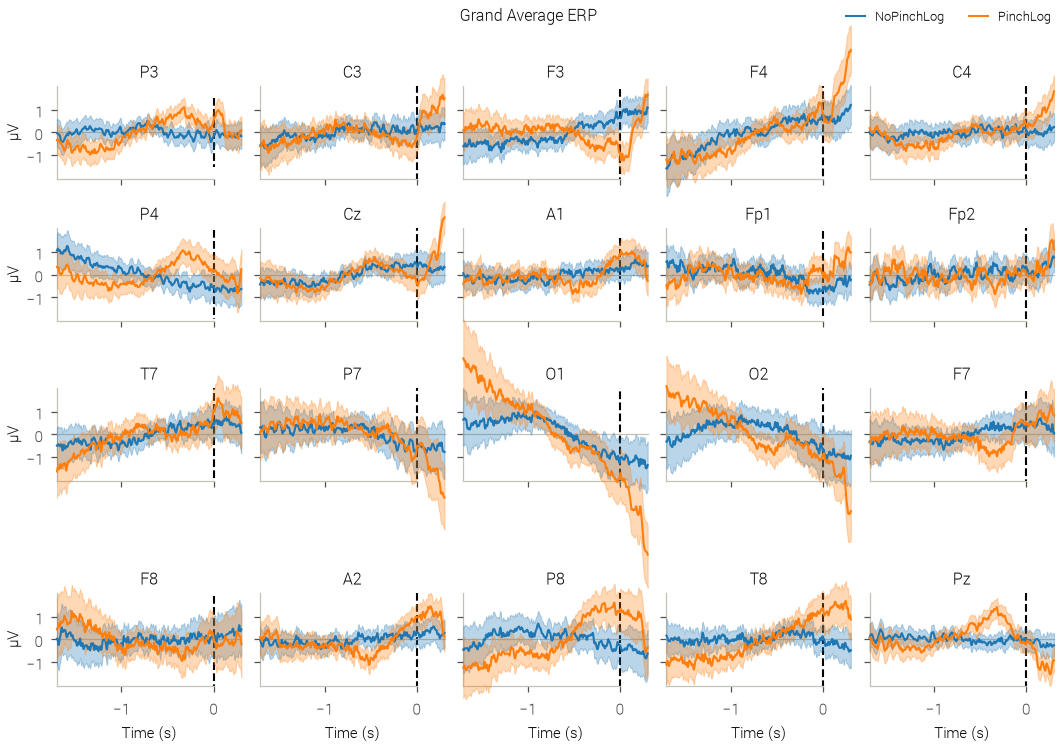

In [5]:
_ = plot_compare_evokeds_grid(epochs, query="((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')", group_by="EventType")

No projector specified for this dataset. Please consider the method self.add_proj.


findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXGeneral, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXNonUnicode, now using 400.
findfont: Failed to find font weight 300 for STIXSizeOneSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeTwoSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeThreeSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFourSym, now using 400.
findfont: Failed to find font weight 300 for STIXSizeFiveSym, now using 400.
findfont: Failed to find font weight 300 for cmmi10, now using 400.
findfont: Failed to find font weight 300 for cmsy10, now using 400.
findfont: Failed to find font weight 300 for cmr10, now using 400.
findfont: Failed to find font weight 300 for cmtt10, now using 400.
findfont: Failed to find font weight 300 for cm

No projector specified for this dataset. Please consider the method self.add_proj.


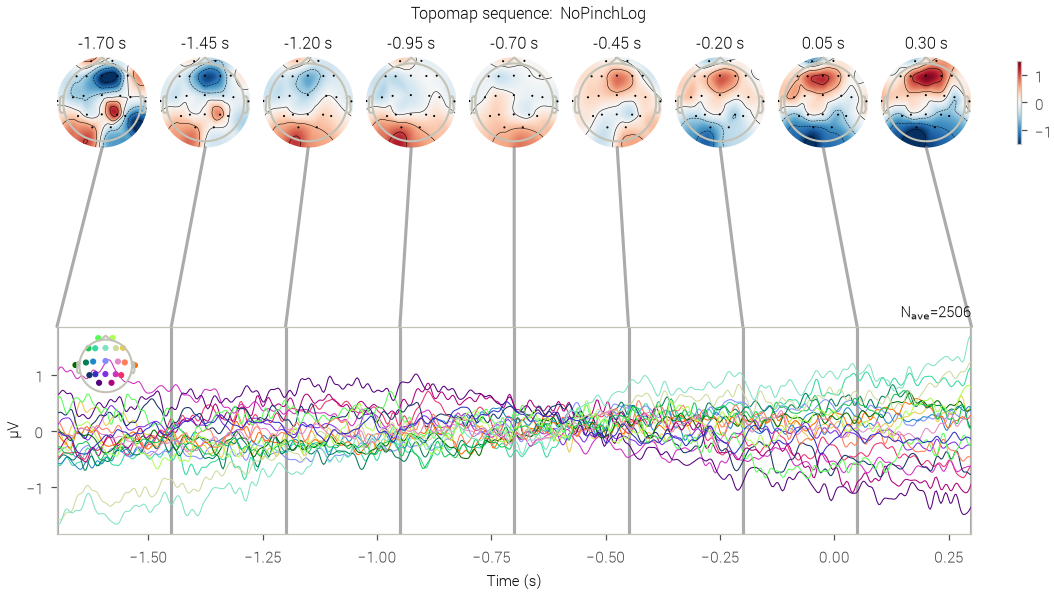

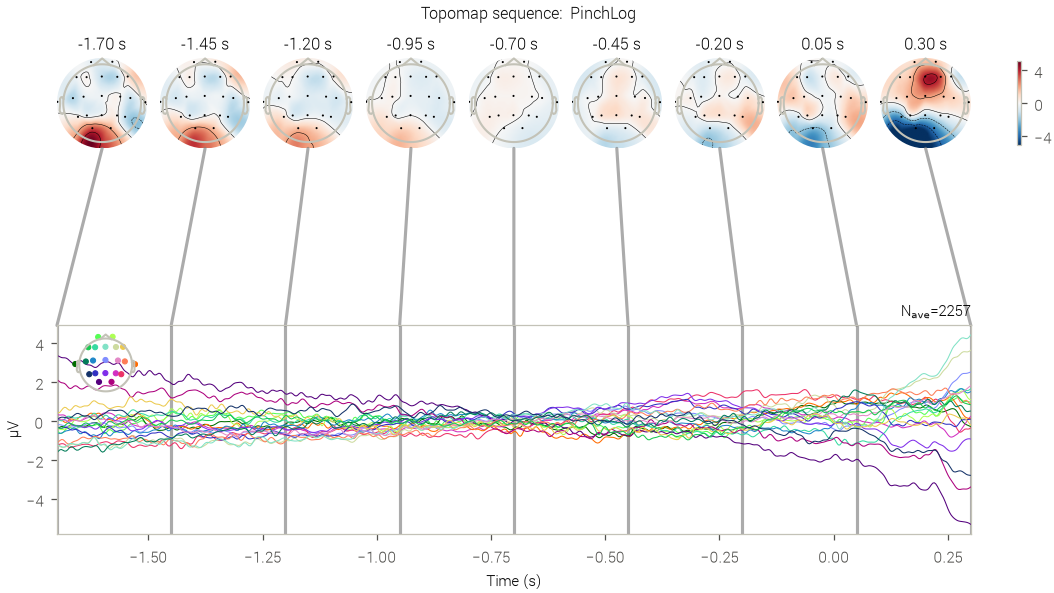

In [6]:
interval = 0.25
_ = plot_joint_grouped(epochs, query="((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')", group_by="EventType", times=[(-1.7 + i*interval) for i in range(int(2/interval+1))], average_window=0.1)

Applying baseline correction (mode: logratio)
Applying baseline correction (mode: logratio)


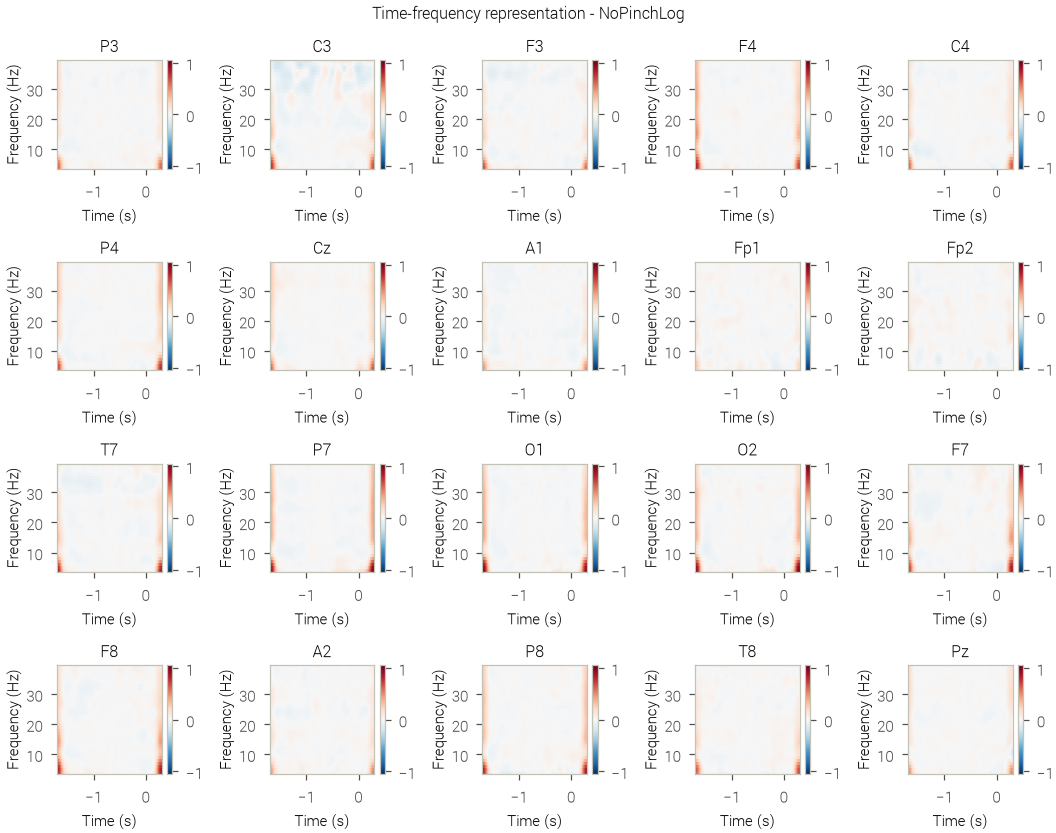

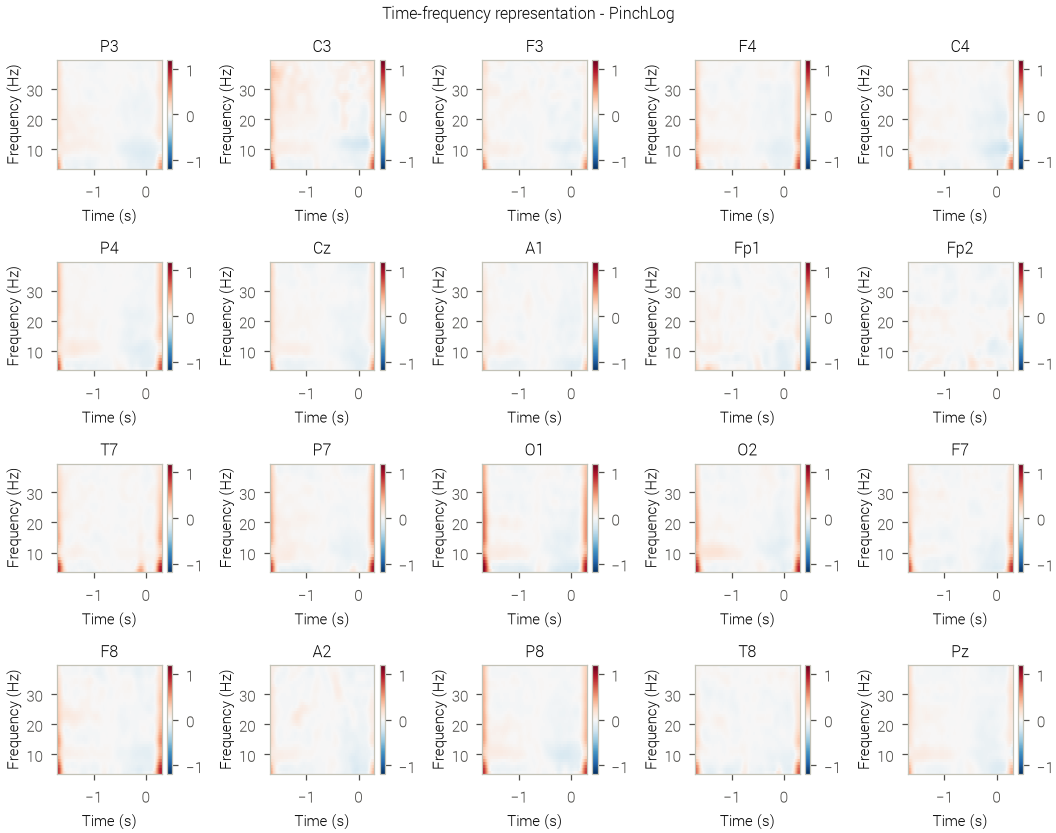

In [7]:
_ = plot_tfr_grouped(epochs, query="((EventType == 'PinchLog') & (PinchType == 'PINCH')) | (EventType == 'NoPinchLog')", group_by="EventType")

## Pinch vs. Observe

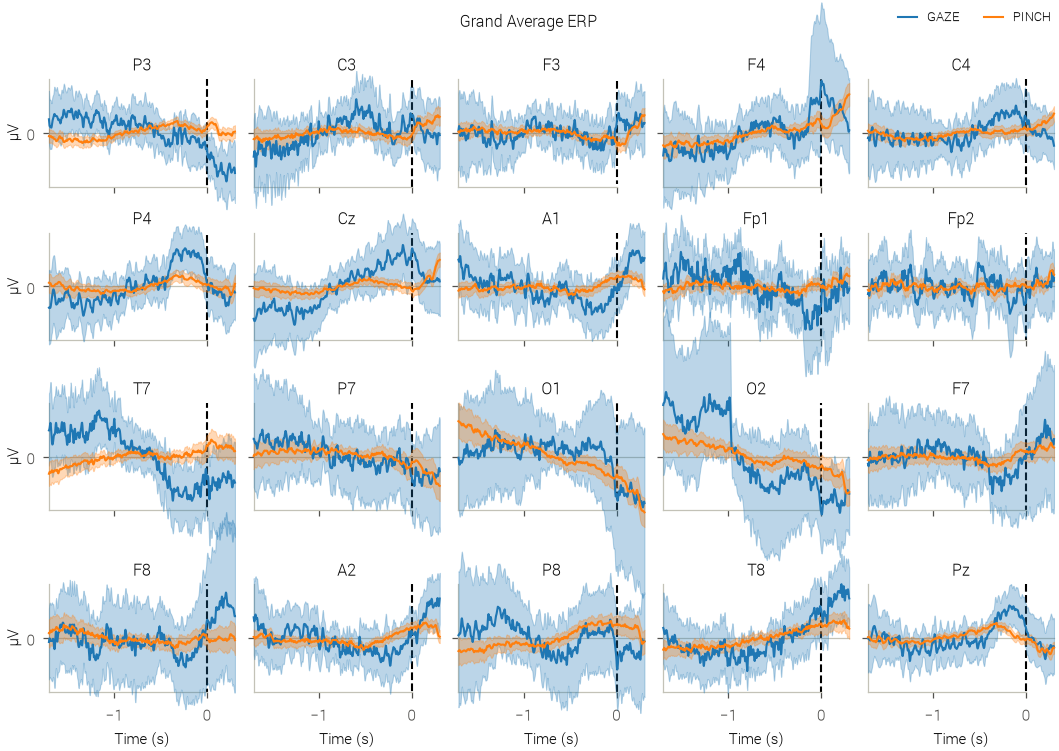

In [8]:
_ = plot_compare_evokeds_grid(epochs, query="((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'GAZE')))", group_by="PinchType")

In [9]:
epochs.metadata

,UnityTimestamp,EventType,EventName,Severity,ExperimentName,ExperimentIndex,timestamp,stream,Eye,State,...,GazeDirection.z,HeadPosition.x,HeadPosition.y,HeadPosition.z,HeadForward.x,HeadForward.y,HeadForward.z,sample,subject,session
1,2026-08-27T14:28:02.9929609+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment1 (Experiments.ExperimentStatic),1.0,13.943777,Experiment.VIBE.GameEventStream,None,None,...,0.992826,0.031525,1.109353,-0.043949,-0.015334,-0.043817,0.998922,62376,subject_21,session_1
4,NaN,NoPinchLog,NaN,NaN,NaN,1.0,16.236269,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,63064,subject_21,session_1
6,2026-08-27T14:28:07.7084045+02:00,PinchLog,PINCH_STIMULUS,MESSAGE,Experiment1 (Experiments.ExperimentStatic),1.0,18.658126,Experiment.VIBE.GameEventStream,None,None,...,0.997981,0.034945,1.110272,-0.044528,-0.004005,-0.037033,0.999306,63790,subject_21,session_1
9,NaN,NoPinchLog,NaN,NaN,NaN,1.0,21.261958,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64572,subject_21,session_1
24,NaN,NoPinchLog,NaN,NaN,NaN,1.0,39.509389,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70046,subject_21,session_1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
79621,NaN,NoPinchLog,NaN,NaN,NaN,NaN,670.048545,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,249574,subject_40,session_1
79634,NaN,NoPinchLog,NaN,NaN,NaN,NaN,675.048545,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,251074,subject_40,session_1
79641,NaN,NoPinchLog,NaN,NaN,NaN,NaN,680.048545,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,252574,subject_40,session_1
79644,NaN,NoPinchLog,NaN,NaN,NaN,NaN,685.048545,NaN,None,None,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,254074,subject_40,session_1


## Movement requirements

## Highlight vs. Observe

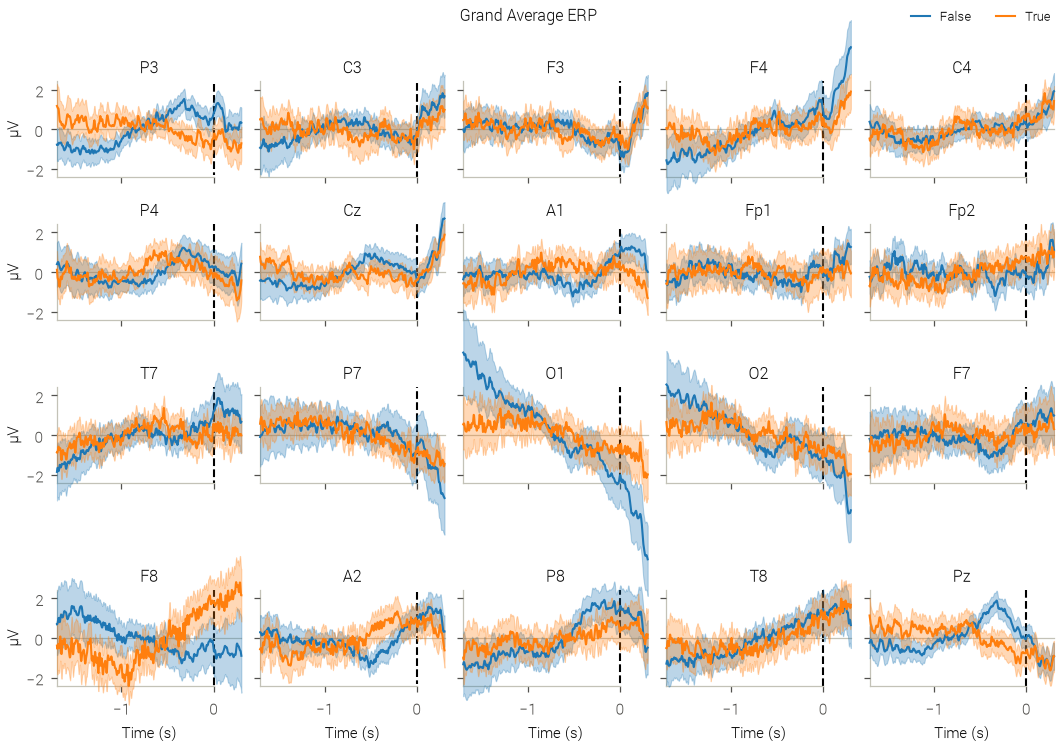

In [10]:
_ = plot_compare_evokeds_grid(epochs, query="((EventType == 'PinchLog') & ((PinchType == 'PINCH')))", group_by="isChoiceStimuli")

## Impact of a virtual hand representation

## Impact of feedback

## Delayed feedback

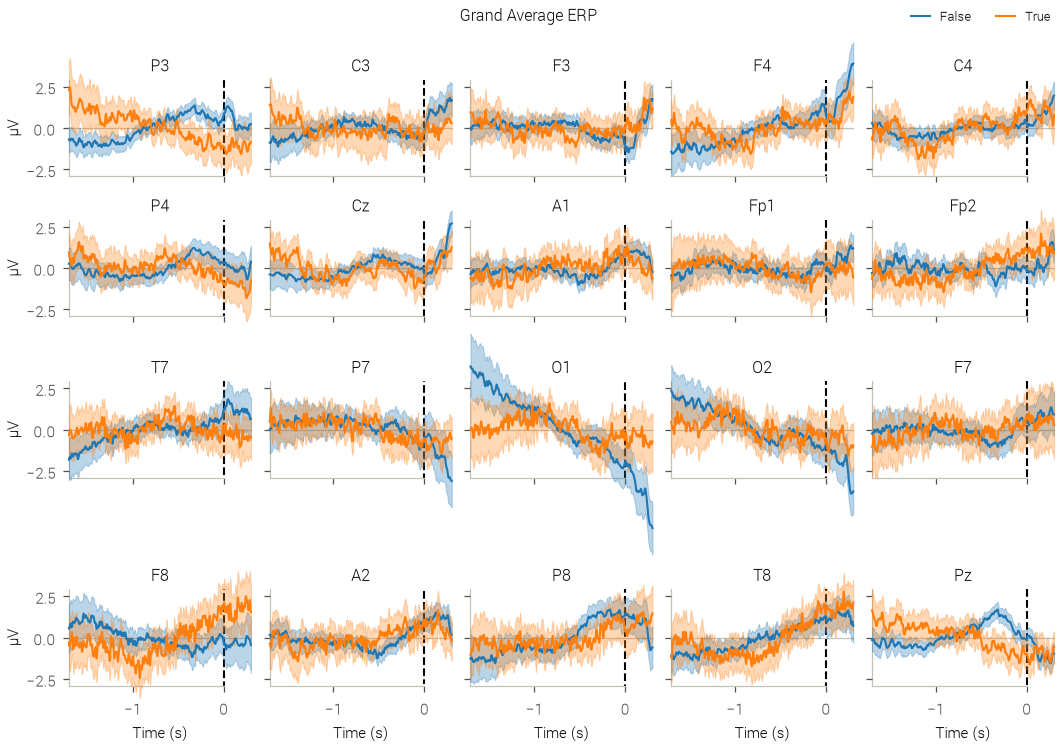

In [11]:
_ = plot_compare_evokeds_grid(epochs, query="((EventType == 'PinchLog') & ((PinchType == 'PINCH')))", group_by="feedbackIsDelayed")

## Error related potentials

C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\IPython\core\events.py:101: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  func(*args, **kwargs)
C:\Users\nicol\github\VIBE\DataAnalysis\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: constrained_layout not applied because axes sizes collapsed to zero.  Try making figure larger or Axes decorations smaller.
  fig.canvas.print_figure(bytes_io, **kw)


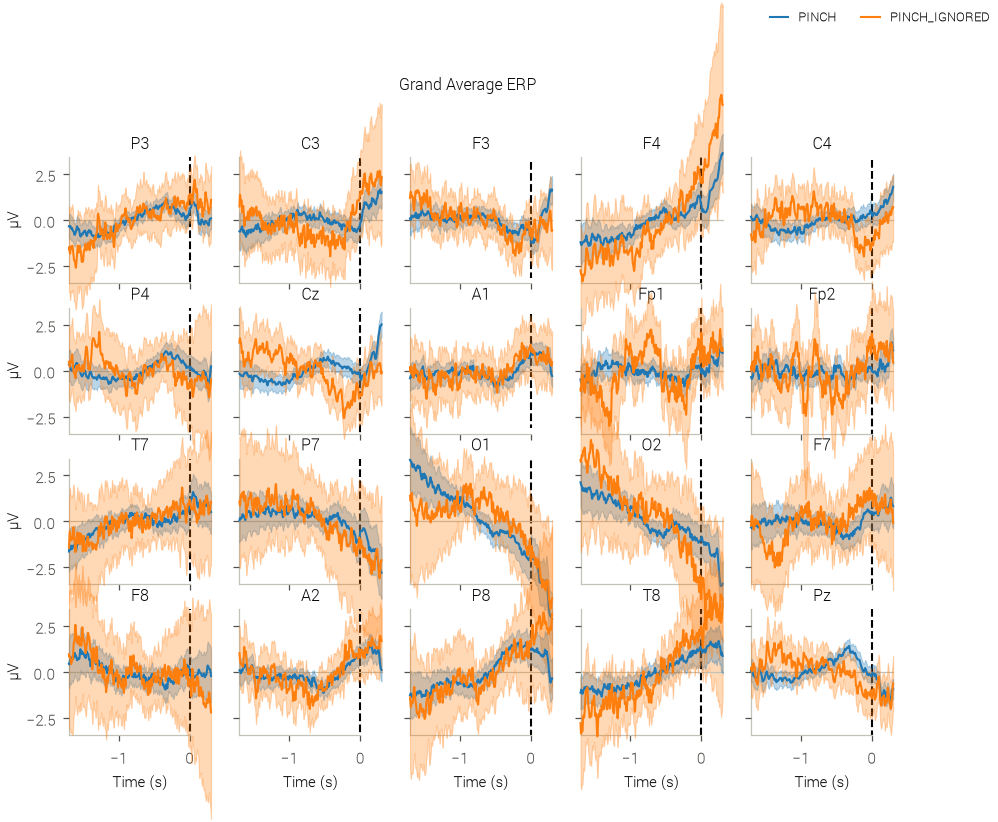

In [12]:
_ = plot_compare_evokeds_grid(epochs, query="((EventType == 'PinchLog') & ((PinchType == 'PINCH') | (PinchType == 'PINCH_IGNORED')))", group_by="PinchType")